# ARTI 403 – Image Processing
## Lab 6: Frequency Domain

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft2, ifft2, ifftshift
from skimage import data
from skimage.transform import resize

## Task 1: Sobel Filters in the Frequency Domain

In [2]:
image = data.camera()
image = resize(image, (256, 256))

sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    cy, cx = ph // 2, pw // 2
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))

F = fft2(image)
Hx = center_embed_kernel(sobel_x, image.shape)
Hy = center_embed_kernel(sobel_y, image.shape)

Gx = ifft2(F * Hx).real
Gy = ifft2(F * Hy).real
magnitude = np.sqrt(Gx**2 + Gy**2)

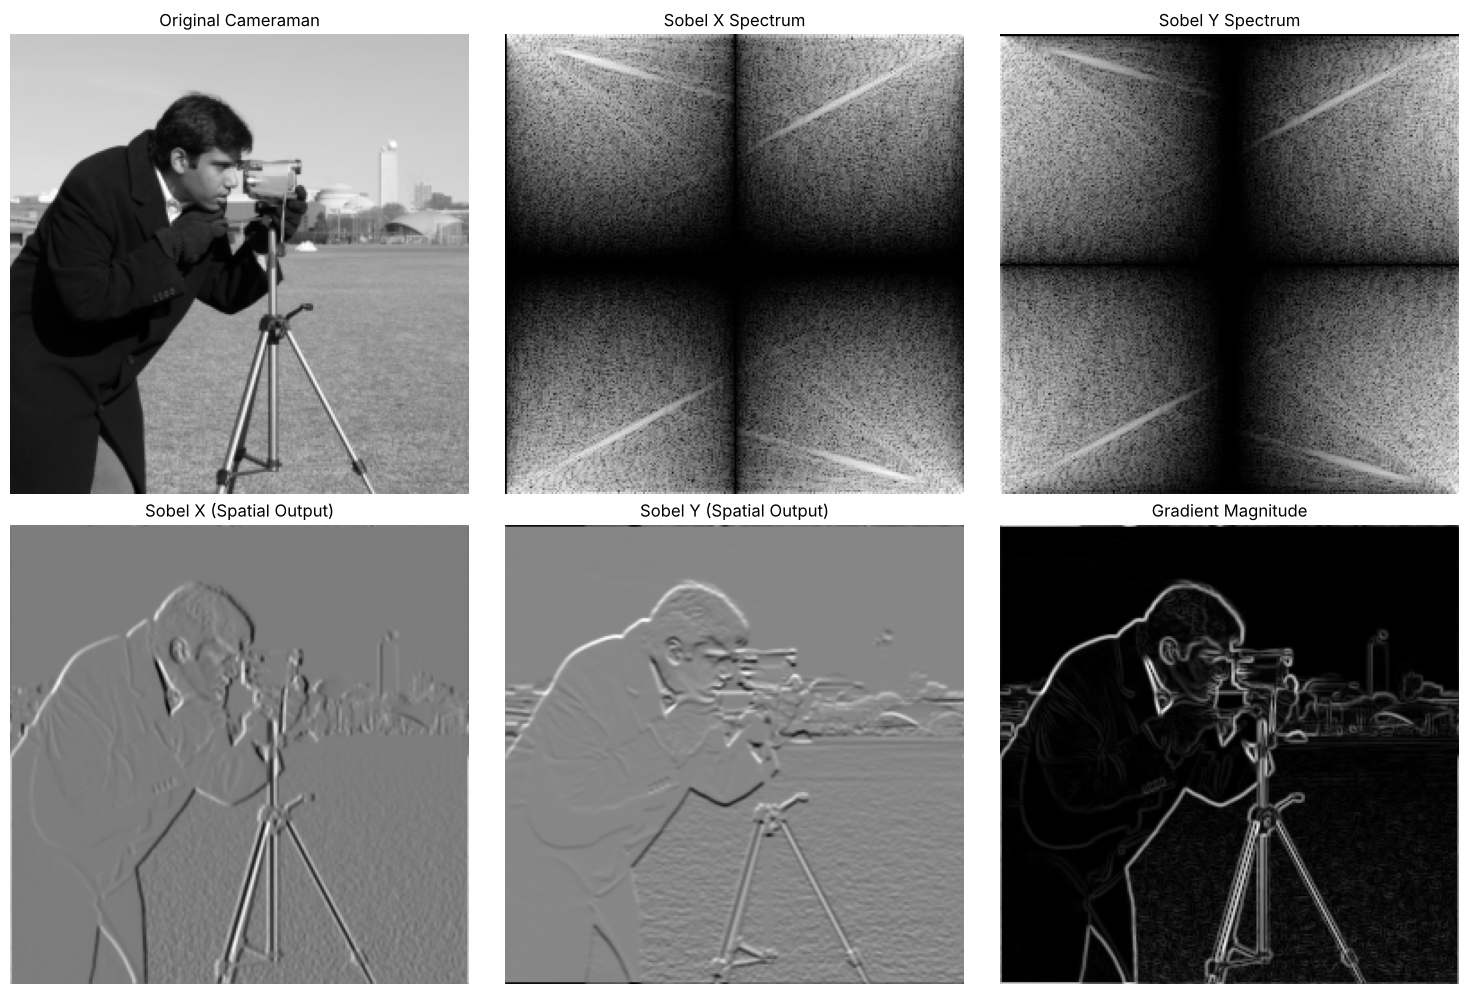

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(15, 10))
ax[0, 0].imshow(image, cmap='gray')
ax[0, 0].set_title('Original Cameraman')
ax[0, 1].imshow(np.log(1 + np.abs(F * Hx)), cmap='gray')
ax[0, 1].set_title('Sobel X Spectrum')
ax[0, 2].imshow(np.log(1 + np.abs(F * Hy)), cmap='gray')
ax[0, 2].set_title('Sobel Y Spectrum')
ax[1, 0].imshow(Gx, cmap='gray')
ax[1, 0].set_title('Sobel X (Spatial Output)')
ax[1, 1].imshow(Gy, cmap='gray')
ax[1, 1].set_title('Sobel Y (Spatial Output)')
ax[1, 2].imshow(magnitude, cmap='gray')
ax[1, 2].set_title('Gradient Magnitude')
for a in ax.ravel():
    a.axis('off')
plt.tight_layout()
plt.show()